In [1]:
import mne

file_path = "../data/raw/S001R01.edf"

raw = mne.io.read_raw_edf(
    file_path,
    preload=True
)

print("raw")
print(raw)

print("INFO")
print(raw.info)

print("Channel names")
print(raw.ch_names)
print(len(raw.ch_names))

print("Sampling frequency:")
print(raw.info["sfreq"])

print("Number of samples:")
print(raw.n_times)

print("Recording duration:")
print(raw.times[-1])

Extracting EDF parameters from ../data/raw/S001R01.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 9759  =      0.000 ...    60.994 secs...
raw
<RawEDF | S001R01.edf, 64 x 9760 (61.0 s), ~4.8 MiB, data loaded>
INFO
<Info | 8 non-empty values
 bads: []
 ch_names: Fc5., Fc3., Fc1., Fcz., Fc2., Fc4., Fc6., C5.., C3.., C1.., ...
 chs: 64 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 80.0 Hz
 meas_date: 2009-08-12 16:15:00 UTC
 nchan: 64
 projs: []
 sfreq: 160.0 Hz
 subject_info: <subject_info | his_id: X, sex: 0, last_name: X>
>
Channel names
['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..', 'Cz..', 'C2..', 'C4..', 'C6..', 'Cp5.', 'Cp3.', 'Cp1.', 'Cpz.', 'Cp2.', 'Cp4.', 'Cp6.', 'Fp1.', 'Fpz.', 'Fp2.', 'Af7.', 'Af3.', 'Afz.', 'Af4.', 'Af8.', 'F7..', 'F5..', 'F3..', 'F1..', 'Fz..', 'F2..', 'F4..', 'F6..', 'F8..', 'Ft7.', 'Ft8.', 'T7..', 'T8..', 'T9..', 'T10.', 'Tp7.', 'Tp8.', 'P7..', 'P5..', 'P3..', 'P1..', 'Pz

In [4]:
print("Extract the EEG data:")
data = raw.get_data()
print(data)

Extract the EEG data:
[[-1.6e-05 -5.6e-05 -5.5e-05 ...  0.0e+00  0.0e+00  0.0e+00]
 [-2.9e-05 -5.4e-05 -5.5e-05 ...  0.0e+00  0.0e+00  0.0e+00]
 [ 2.0e-06 -2.7e-05 -2.9e-05 ...  0.0e+00  0.0e+00  0.0e+00]
 ...
 [-2.1e-05 -1.2e-05  2.0e-06 ...  0.0e+00  0.0e+00  0.0e+00]
 [-1.1e-05  1.0e-06  1.8e-05 ...  0.0e+00  0.0e+00  0.0e+00]
 [ 1.5e-05  2.1e-05  3.5e-05 ...  0.0e+00  0.0e+00  0.0e+00]]


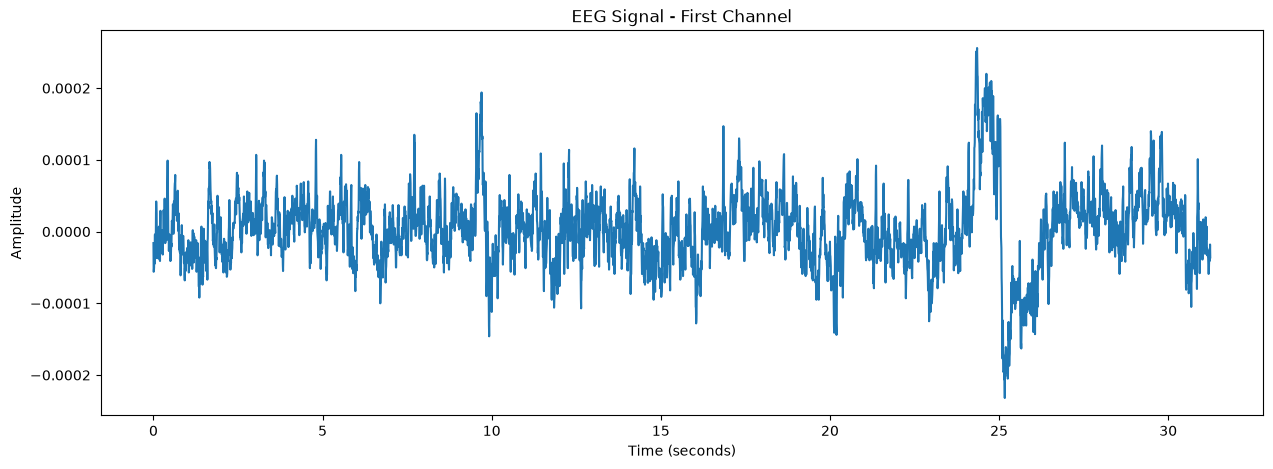

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    raw.times[:5000],
    data[0, :5000]
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("EEG Signal - First Channel")

plt.show()

Using matplotlib as 2D backend.


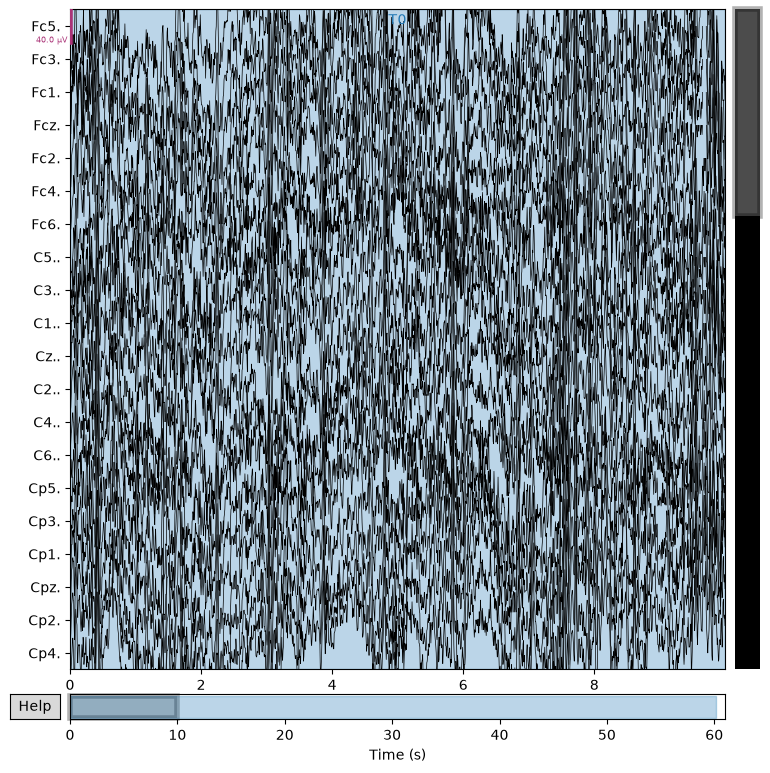

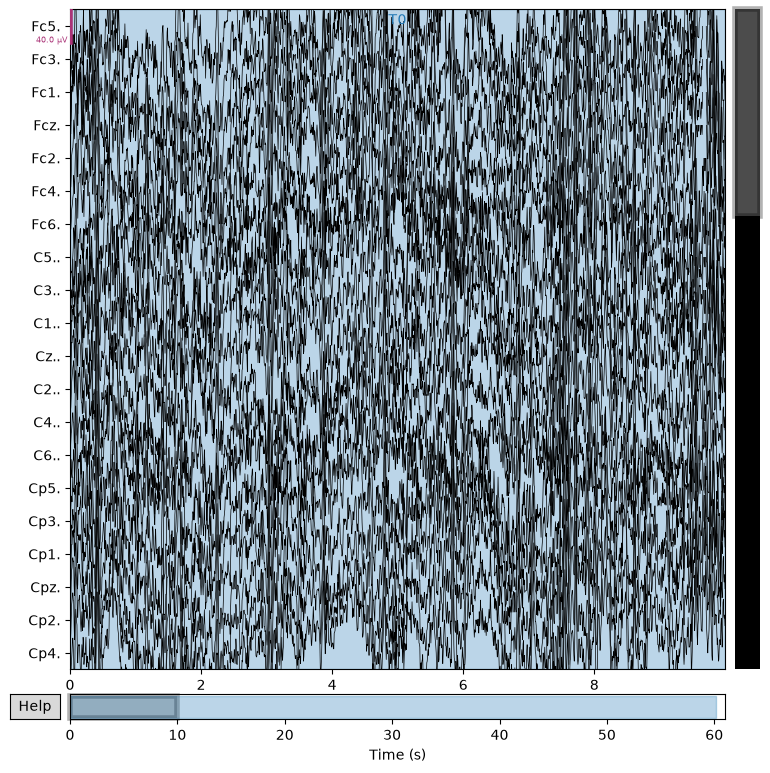

In [6]:
raw.plot()

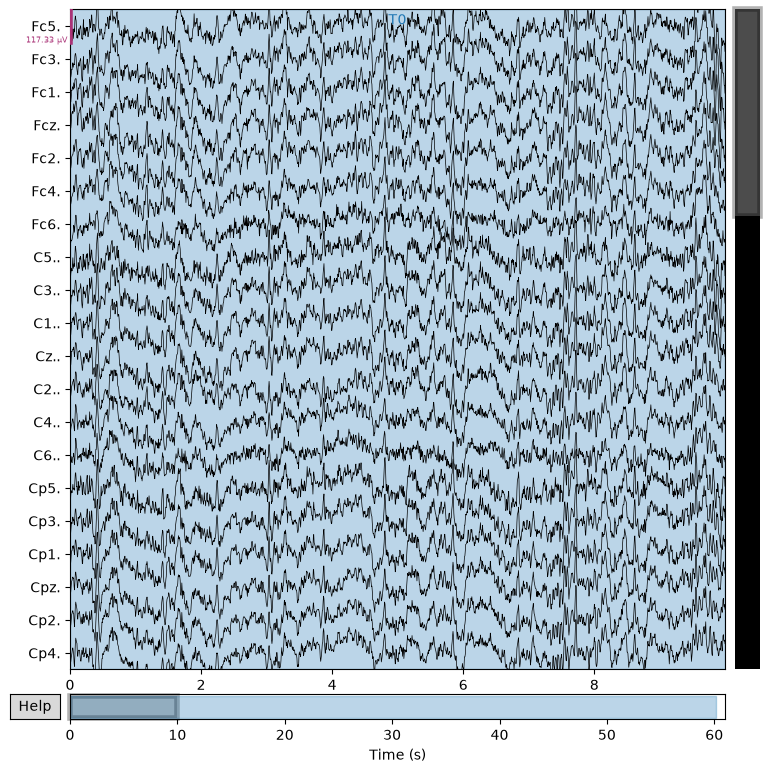

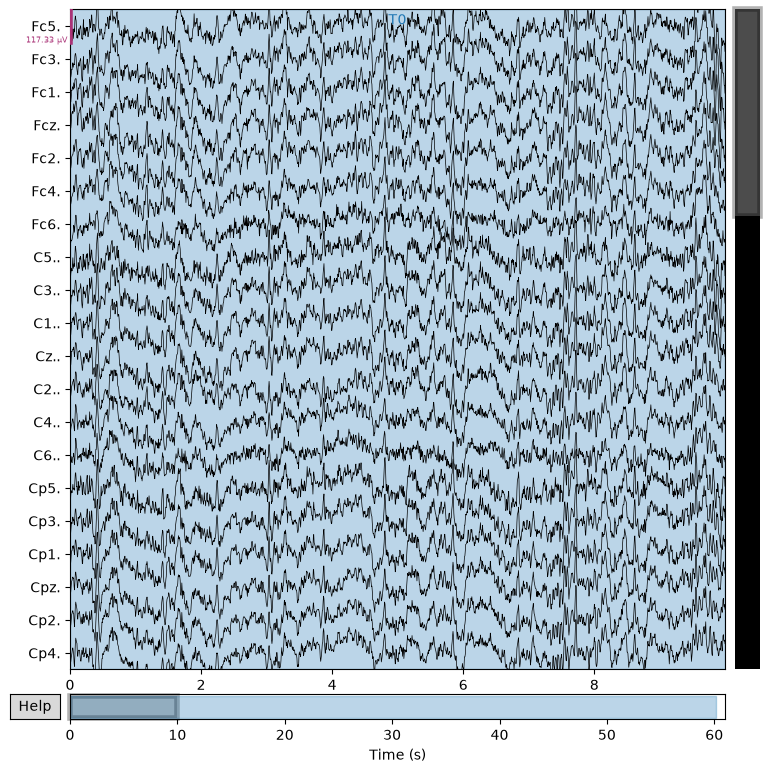

In [7]:
raw.plot(
    n_channels=20,
    duration=10,
    scalings="auto"
)

Visualize a specific channel

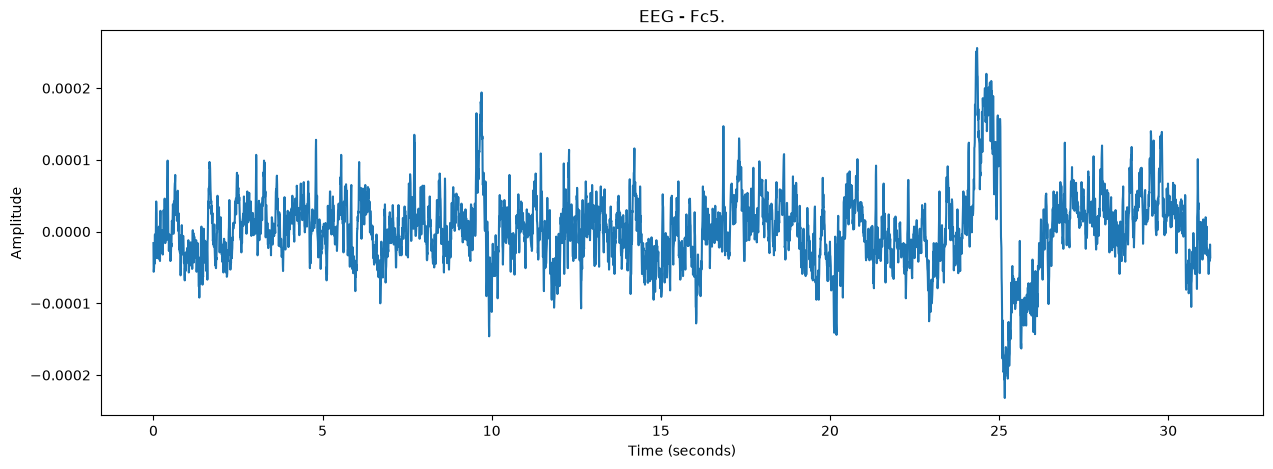

In [8]:
channel_name = raw.ch_names[0]

channel_data = raw.get_data(
    picks=[channel_name]
)[0]

plt.figure(figsize=(15, 5))

plt.plot(
    raw.times[:5000],
    channel_data[:5000]
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title(f"EEG - {channel_name}")

plt.show()

Perform basic filtering

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 60 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 60.00 Hz
- Upper transition bandwidth: 15.00 Hz (-6 dB cutoff frequency: 67.50 Hz)
- Filter length: 529 samples (3.306 s)



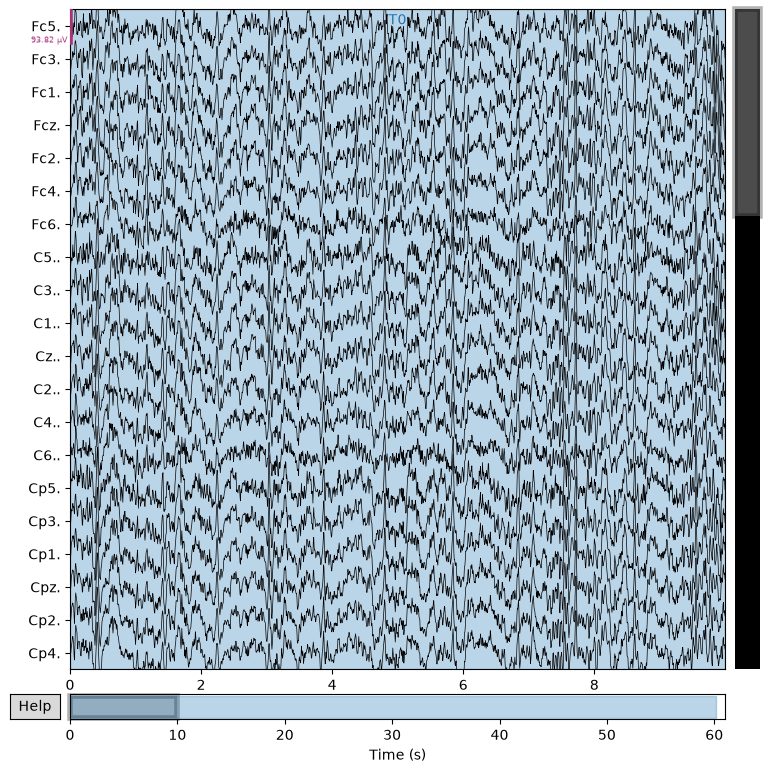

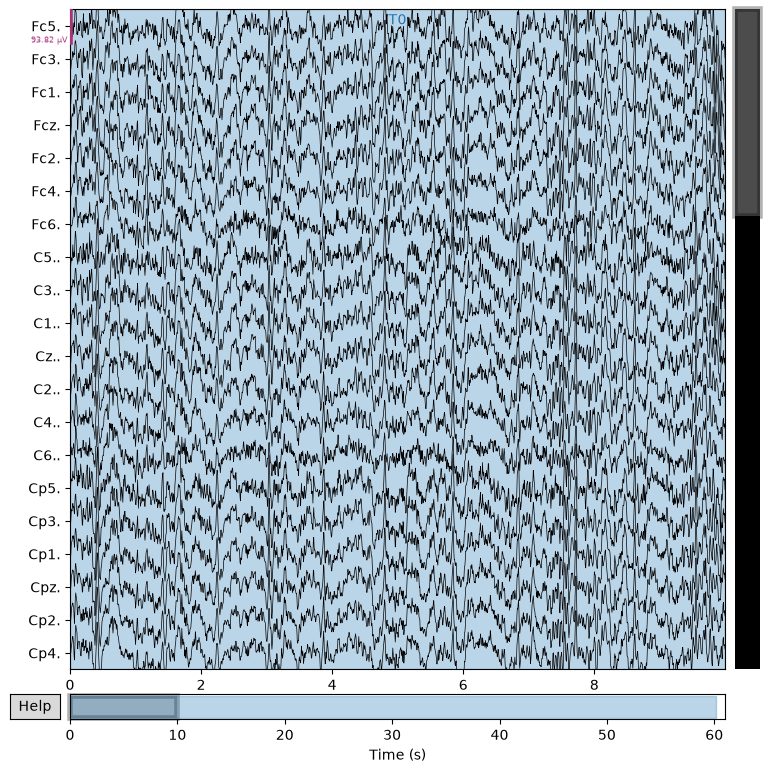

In [10]:
raw_filtered = raw.copy()

raw_filtered.filter(
    l_freq=1,
    h_freq=60
)

raw_filtered.plot(
    n_channels=20,
    duration=10,
    scalings="auto"
)

In [11]:
raw_filtered.notch_filter(freqs=50)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband edge: 50.62 Hz
- Upper transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 50.88 Hz)
- Filter length: 1057 samples (6.606 s)



<RawEDF | S001R01.edf, 64 x 9760 (61.0 s), ~4.8 MiB, data loaded>

Visualize the frequency spectrum

Effective window size : 12.800 (s)
Plotting power spectral density (dB=True).


C:\Users\mitta\AppData\Local\Temp\ipykernel_4152\4108630121.py:1: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw.compute_psd().plot()
c:\Users\mitta\Desktop\SUB\Capstone\EEGRehab\.venv\Lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


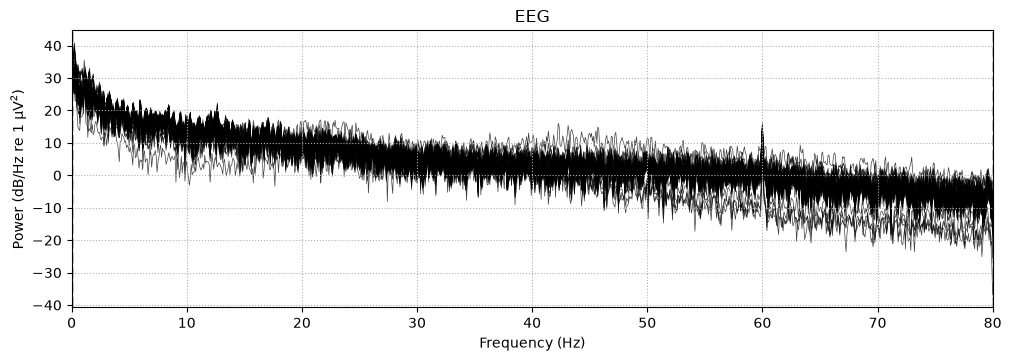

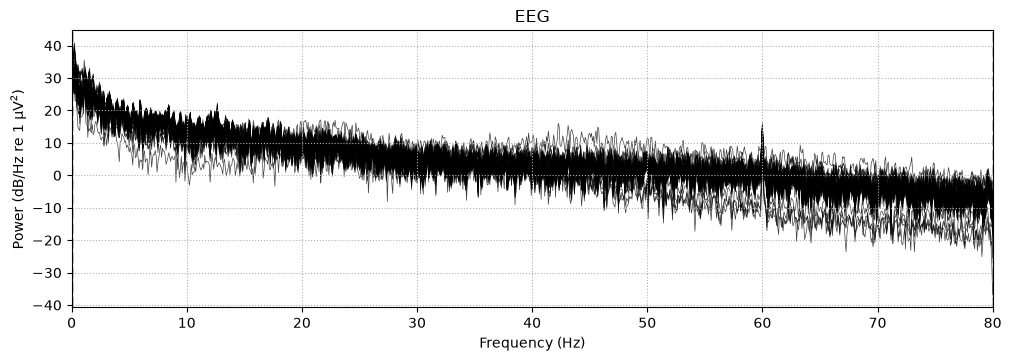

In [12]:
raw.compute_psd().plot()

In [13]:
psd = raw.compute_psd()

print(psd)

Effective window size : 12.800 (s)
<Power Spectrum (from Raw, welch method) | 64 channels × 1025 freqs, 0.0-80.0 Hz>


Understand events/annotations

In [14]:
print(raw.annotations)
events, event_dict = mne.events_from_annotations(raw)

print(events)
print(event_dict)

<Annotations | 1 segment: T0 (1)>
Used Annotations descriptions: [np.str_('T0')]
[[0 0 1]]
{np.str_('T0'): 1}


In [17]:
epochs = mne.Epochs
print(epochs)

<class 'mne.epochs.Epochs'>
